# Hotel Booking Project


## 1. Import Libraries and Load Dataset

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

file_path = r"C:\Users\nakib\Downloads\hotel_booking_updated.csv"

df = pd.read_csv(file_path)
print("Dataset loaded successfully")


Dataset loaded successfully


## 2. View the Dataset

In [14]:
df

,hotel,is_canceled,reservation_status_date,lead_time,stays_in_weekend_nights,stays_in_week_nights,market_segment,is_repeated_guest,reserved_room_type,customer_type,average_daily_rate,reservation_status
0,Resort Hotel,0,7/1/2015,342,0,0,Direct,0,C,Transient,0.00,Check-Out
1,Resort Hotel,0,7/1/2015,737,0,0,Direct,0,C,Transient,0.00,Check-Out
2,Resort Hotel,0,7/2/2015,7,0,1,Direct,0,A,Transient,75.00,Check-Out
3,Resort Hotel,0,7/2/2015,13,0,1,Corporate,0,A,Transient,75.00,Check-Out
4,Resort Hotel,0,7/3/2015,14,0,2,Online TA,0,A,Transient,98.00,Check-Out
...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,9/6/2017,23,2,5,Offline TA/TO,0,A,Transient,96.14,Check-Out
119386,City Hotel,0,9/7/2017,102,2,5,Online TA,0,E,Transient,225.43,Check-Out
119387,City Hotel,0,9/7/2017,34,2,5,Online TA,0,D,Transient,157.71,Check-Out
119388,City Hotel,0,9/7/2017,109,2,5,Online TA,0,A,Transient,104.40,Check-Out


## 3. Basic Dataset Information

In [15]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nData types:")
print(df.dtypes)


Shape: (119390, 12)

Columns:
Index(['hotel', 'is_canceled', 'reservation_status_date', 'lead_time',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'market_segment',
       'is_repeated_guest', 'reserved_room_type', 'customer_type',
       'average_daily_rate', 'reservation_status'],
      dtype='str')

Data types:
hotel                          str
is_canceled                  int64
reservation_status_date        str
lead_time                    int64
stays_in_weekend_nights      int64
stays_in_week_nights         int64
market_segment                 str
is_repeated_guest            int64
reserved_room_type             str
customer_type                  str
average_daily_rate         float64
reservation_status             str
dtype: object


## 4. Missing Values and Duplicate Rows

In [16]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
hotel                      0
is_canceled                0
reservation_status_date    0
lead_time                  0
stays_in_weekend_nights    0
stays_in_week_nights       0
market_segment             0
is_repeated_guest          0
reserved_room_type         0
customer_type              0
average_daily_rate         0
reservation_status         0
dtype: int64

Duplicate rows: 38051


In [17]:

df['is_canceled'].unique()


array([0, 1])

In [18]:

df['is_canceled'].sum()


np.int64(44224)

In [19]:

len(df['is_canceled'])


119390

In [20]:

df['is_canceled'].sum()/len(df['is_canceled'])


np.float64(0.37041628277075134)

In [21]:

df['market_segment'].value_counts(normalize=True)


market_segment
Online TA        0.473046
Offline TA/TO    0.202856
Groups           0.165935
Direct           0.105587
Corporate        0.044350
Complementary    0.006223
Aviation         0.001985
Undefined        0.000017
Name: proportion, dtype: float64

In [22]:

df['is_canceled'].value_counts(normalize=True)


is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

# Question 1 

In [23]:
cancellation_rate = df['is_canceled'].sum()/len(df['is_canceled'])

print("Overall cancellation rate:", round(cancellation_rate * 100, 2), "%")


Overall cancellation rate: 37.04 %


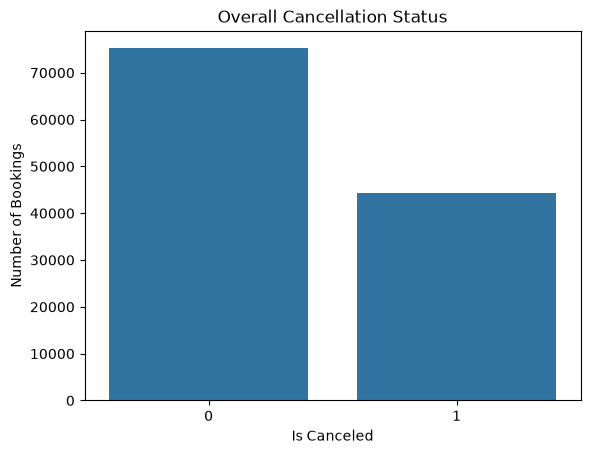

In [24]:
sns.countplot(data=df, x='is_canceled')
plt.title("Overall Cancellation Status")
plt.xlabel("Is Canceled")
plt.ylabel("Number of Bookings")
plt.show()


# Question 2 

In [25]:
hotel_cancellation = df.groupby('hotel')['is_canceled'].mean()

print("Cancellation rate by hotel type:")
print(hotel_cancellation)


Cancellation rate by hotel type:
hotel
City Hotel      0.417270
Resort Hotel    0.277634
Name: is_canceled, dtype: float64


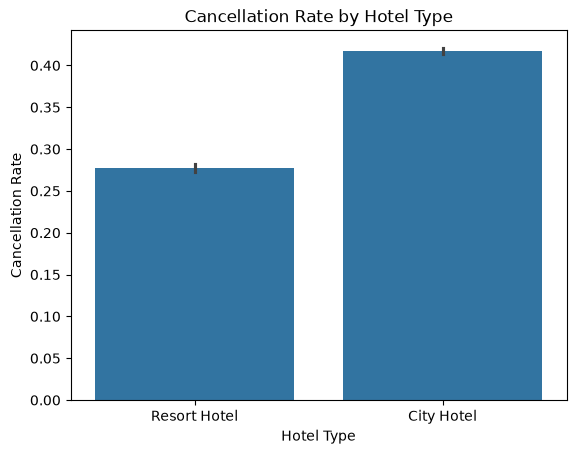

In [26]:
sns.barplot(data=df, x='hotel', y='is_canceled')
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate")
plt.show()


# Question 3 


In [27]:
df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, 180, 365, float('inf')],
    labels=[
        'Immediate',
        'Monthly',
        'Medium-Term',
        'Extended',
        'Long-Term',
        'Very Long-Term'
    ]
)

df[['lead_time', 'lead_time_group']].head()


,lead_time,lead_time_group
0,342,Long-Term
1,737,Very Long-Term
2,7,Immediate
3,13,Monthly
4,14,Monthly


In [28]:
lead_cancellation = df.groupby('lead_time_group', observed=True)['is_canceled'].mean()

print("Cancellation rate by lead time group:")
print(lead_cancellation)


Cancellation rate by lead time group:
lead_time_group
Immediate         0.096323
Monthly           0.278639
Medium-Term       0.376984
Extended          0.447105
Long-Term         0.554540
Very Long-Term    0.676620
Name: is_canceled, dtype: float64


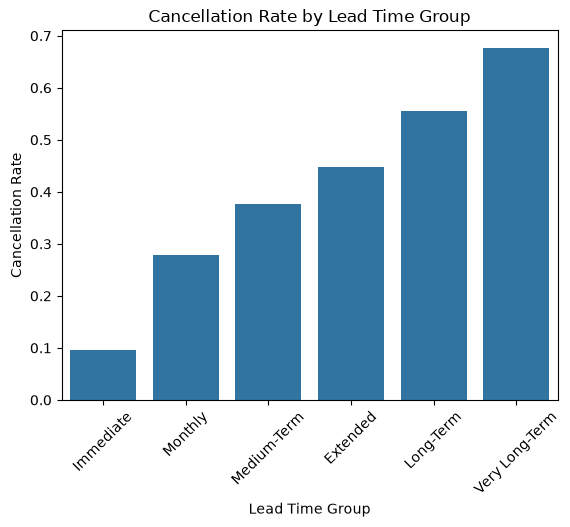

In [29]:
sns.barplot(
    x=lead_cancellation.index,
    y=lead_cancellation.values
)
plt.title("Cancellation Rate by Lead Time Group")
plt.xlabel("Lead Time Group")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation=45)
plt.show()


# Question 4

In [30]:
market_cancellation = df.groupby('market_segment')['is_canceled'].mean()

print("Cancellation rate by market segment:")
print(market_cancellation.sort_values(ascending=False))


Cancellation rate by market segment:
market_segment
Undefined        1.000000
Groups           0.610620
Online TA        0.367211
Offline TA/TO    0.343160
Aviation         0.219409
Corporate        0.187347
Direct           0.153419
Complementary    0.130552
Name: is_canceled, dtype: float64


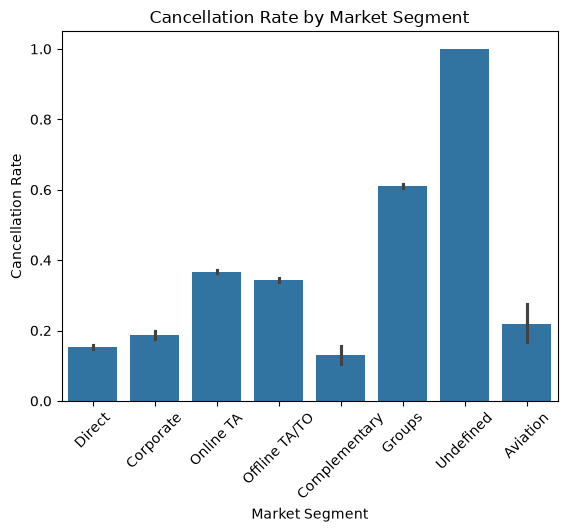

In [31]:
sns.barplot(data=df, x='market_segment', y='is_canceled')
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation=45)
plt.show()


# Question 5 


In [32]:
df['adr_group'] = pd.cut(
    df['average_daily_rate'],
    bins=3,
    labels=['low', 'medium', 'high']
)

df[['average_daily_rate', 'adr_group']].head()


,average_daily_rate,adr_group
0,0.0,low
1,0.0,low
2,75.0,low
3,75.0,low
4,98.0,low


In [33]:
adr_cancellation = df.groupby('adr_group', observed=True)['is_canceled'].mean()

print("Cancellation rate by ADR group:")
print(adr_cancellation)


Cancellation rate by ADR group:
adr_group
low     0.370411
high    1.000000
Name: is_canceled, dtype: float64


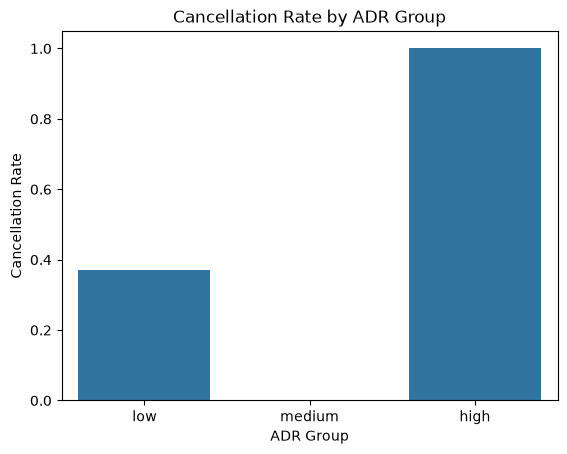

In [34]:
sns.barplot(
    x=adr_cancellation.index,
    y=adr_cancellation.values
)
plt.title("Cancellation Rate by ADR Group")
plt.xlabel("ADR Group")
plt.ylabel("Cancellation Rate")
plt.show()


# Question 6 

In [35]:
customer_cancellation = df.groupby('customer_type')['is_canceled'].mean()

print("Cancellation rate by customer type:")
print(customer_cancellation.sort_values(ascending=False))


Cancellation rate by customer type:
customer_type
Transient          0.407463
Contract           0.309617
Transient-Party    0.254299
Group              0.102253
Name: is_canceled, dtype: float64


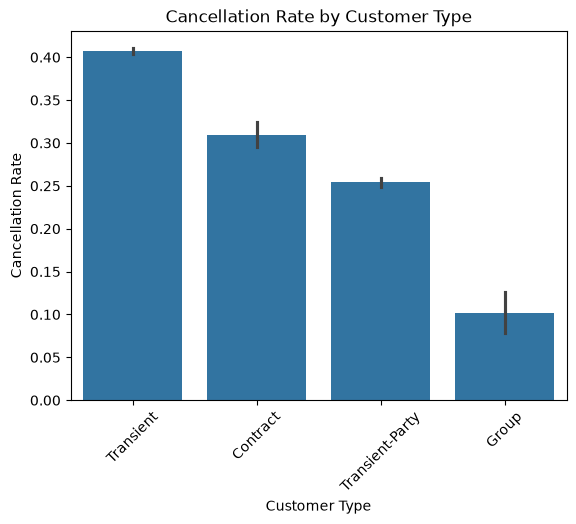

In [36]:
sns.barplot(data=df, x='customer_type', y='is_canceled')
plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation=45)
plt.show()


# Question 7 

In [37]:
room_cancellation = df.groupby('reserved_room_type')['is_canceled'].mean()

print("Cancellation rate by room type:")
print(room_cancellation.sort_values(ascending=False))


Cancellation rate by room type:
reserved_room_type
P    1.000000
H    0.407654
A    0.391074
G    0.364374
L    0.333333
C    0.330472
B    0.329159
D    0.317796
F    0.303763
E    0.292884
Name: is_canceled, dtype: float64


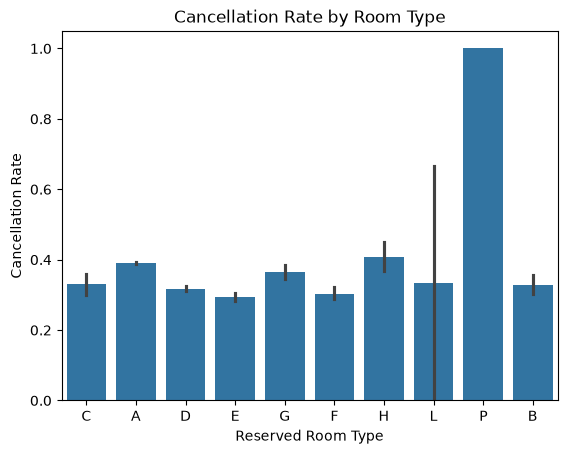

In [38]:
sns.barplot(data=df, x='reserved_room_type', y='is_canceled')
plt.title("Cancellation Rate by Room Type")
plt.xlabel("Reserved Room Type")
plt.ylabel("Cancellation Rate")
plt.show()


# Question 8 

Cancellation Rate by Guest Type:
guest_type
New Guest         37.785084
Repeated Guest    14.488189
Name: is_canceled, dtype: float64


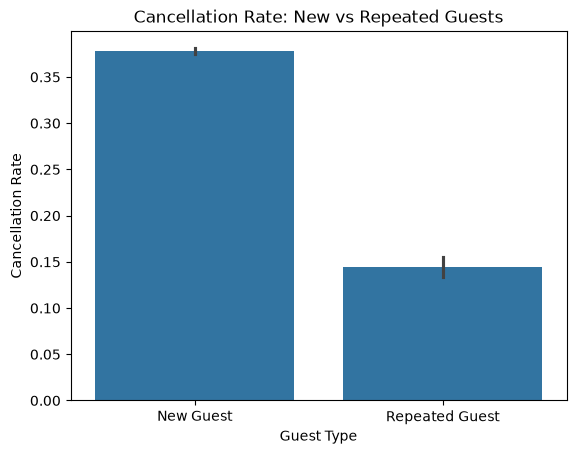

In [56]:
df['guest_type'] = pd.cut(
    df['is_repeated_guest'],
    bins=[-1, 0, 1],
    labels=['New Guest', 'Repeated Guest']
)

# Cancellation rate by guest type
guest_cancellation = df.groupby('guest_type')['is_canceled'].mean()

print("Cancellation Rate by Guest Type:")
print(guest_cancellation * 100)

# Bar plot
sns.barplot(data=df, x='guest_type', y='is_canceled')

plt.title('Cancellation Rate: New vs Repeated Guests')
plt.xlabel('Guest Type')
plt.ylabel('Cancellation Rate')
plt.show()

In [40]:
guest_cancellation = df.groupby('guest_type')['is_canceled'].mean()

print("Cancellation rate by guest type:")
print(guest_cancellation)


Cancellation rate by guest type:
guest_type
New Guest         0.377851
Repeated Guest    0.144882
Name: is_canceled, dtype: float64


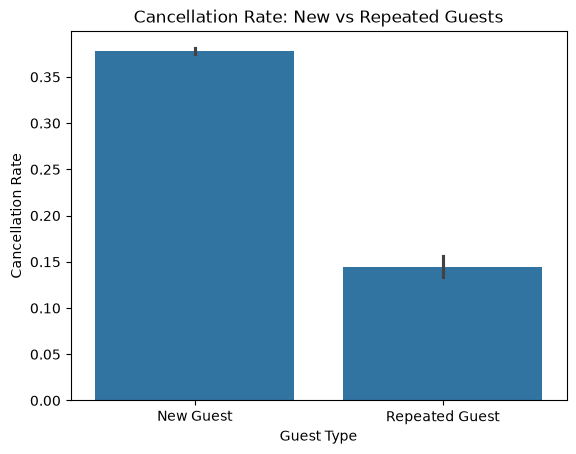

In [41]:
sns.barplot(data=df, x='guest_type', y='is_canceled')
plt.title("Cancellation Rate: New vs Repeated Guests")
plt.xlabel("Guest Type")
plt.ylabel("Cancellation Rate")
plt.show()


# Question 9 

In [42]:
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

df['month'] = df['reservation_status_date'].dt.month

monthly_cancellation = df.groupby('month')['is_canceled'].mean()

print("Monthly cancellation rate:")
print(monthly_cancellation)


Monthly cancellation rate:
month
1     0.567456
2     0.458833
3     0.373412
4     0.347035
5     0.304542
6     0.313861
7     0.360895
8     0.238955
9     0.284590
10    0.371982
11    0.377824
12    0.476622
Name: is_canceled, dtype: float64


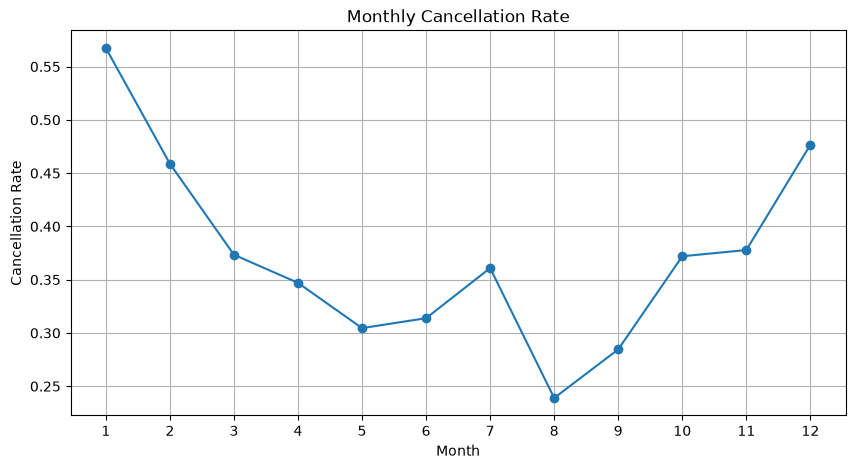

In [43]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_cancellation.index,
    monthly_cancellation.values,
    marker='o'
)

plt.title("Monthly Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate")
plt.xticks(range(1,13))
plt.grid()
plt.show()


# Question 10 

In [44]:
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

df['revenue'] = (
    df['average_daily_rate'] *
    df['total_nights']
)

df[['average_daily_rate', 'total_nights', 'revenue']].head()


,average_daily_rate,total_nights,revenue
0,0.0,0,0.0
1,0.0,0,0.0
2,75.0,1,75.0
3,75.0,1,75.0
4,98.0,2,196.0


In [45]:
monthly_revenue = df.groupby('month')['revenue'].sum()

print("Monthly revenue:")
print(monthly_revenue)


Monthly revenue:
month
1     3126714.23
2     2729646.49
3     3206682.04
4     3673337.72
5     3834367.30
6     3824548.13
7     5522156.56
8     6098155.71
9     3703882.73
10    2979773.43
11    2124259.76
12    1899973.43
Name: revenue, dtype: float64


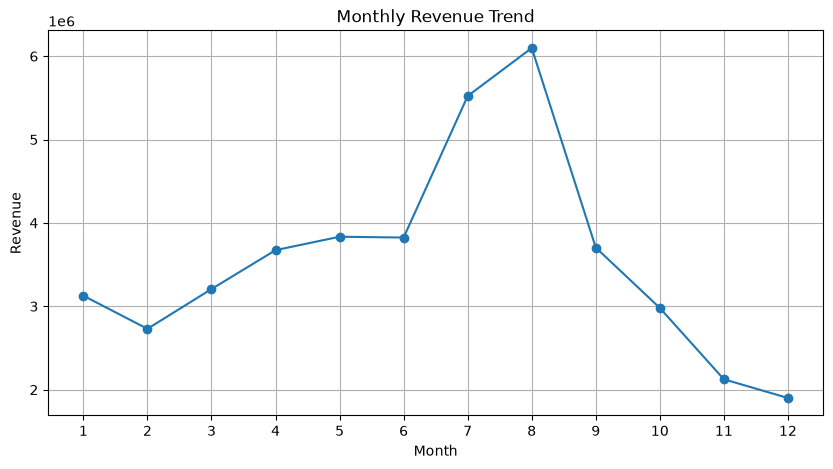

In [46]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o'
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1,13))
plt.grid()
plt.show()


# Question 11 

In [47]:
df['potential_lost_revenue'] = (
    df['average_daily_rate'] *
    df['total_nights'] *
    df['is_canceled']
)

total_lost_revenue = df['potential_lost_revenue'].sum()

print(
    "Total potential revenue lost:",
    round(total_lost_revenue, 2)
)


Total potential revenue lost: 16727237.12


In [48]:
monthly_lost_revenue = df.groupby('month')['potential_lost_revenue'].sum()

print("Monthly potential revenue lost:")
print(monthly_lost_revenue)


Monthly potential revenue lost:
month
1     2073245.98
2     1676624.35
3     1652083.61
4     1597370.40
5     1494824.96
6     1371498.70
7     1700425.92
8     1134394.40
9      956955.83
10     999624.91
11     966747.02
12    1103441.04
Name: potential_lost_revenue, dtype: float64


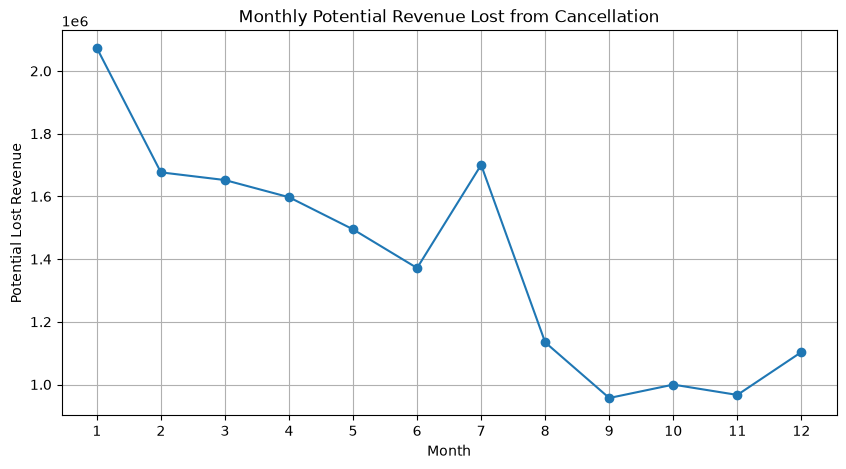

In [49]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_lost_revenue.index,
    monthly_lost_revenue.values,
    marker='o'
)

plt.title("Monthly Potential Revenue Lost from Cancellation")
plt.xlabel("Month")
plt.ylabel("Potential Lost Revenue")
plt.xticks(range(1,13))
plt.grid()
plt.show()


# Question 12



In [50]:
# Correlation of numeric variables with average_daily_rate

correlation = df.corr(numeric_only=True)['average_daily_rate'].sort_values(
    ascending=False
)

correlation


average_daily_rate         1.000000
revenue                    0.565766
potential_lost_revenue     0.302289
total_nights               0.067945
stays_in_week_nights       0.065237
stays_in_weekend_nights    0.049342
is_canceled                0.047557
month                      0.010861
lead_time                 -0.063077
is_repeated_guest         -0.134314
Name: average_daily_rate, dtype: float64

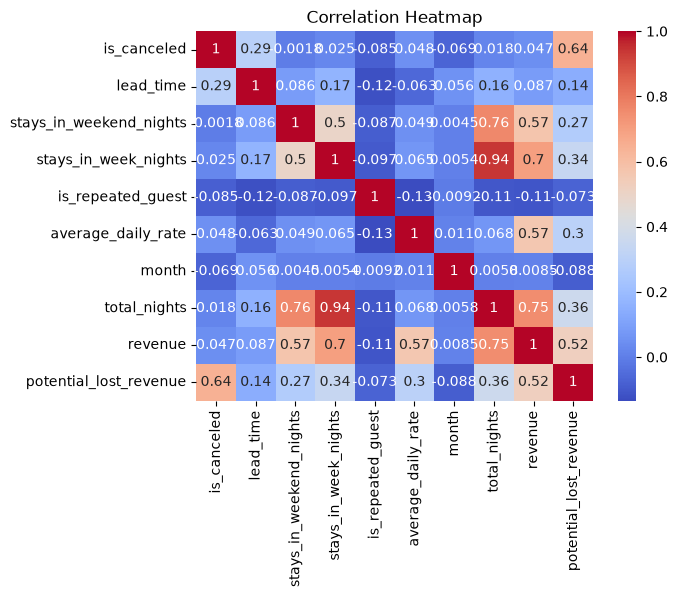

In [51]:
# Correlation heatmap, following the 3sept.ipynb class example

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()


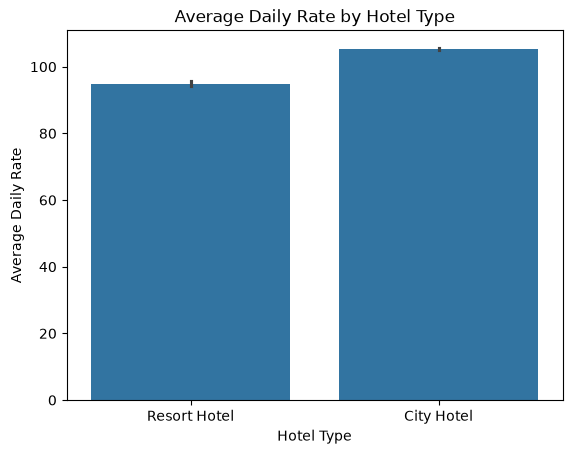

In [52]:
# Relationship between hotel type and average daily rate,
# following the barplot method used in 3sept.ipynb

sns.barplot(
    data=df,
    x='hotel',
    y='average_daily_rate'
)

plt.title("Average Daily Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate")
plt.show()


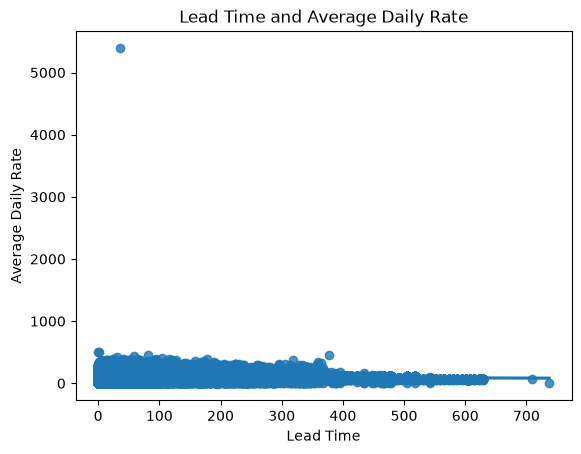

In [53]:
# Regression relationship using the Seaborn approach
# to examine whether lead time can help explain ADR.

sns.regplot(
    data=df,
    x='lead_time',
    y='average_daily_rate'
)

plt.title("Lead Time and Average Daily Rate")
plt.xlabel("Lead Time")
plt.ylabel("Average Daily Rate")
plt.show()


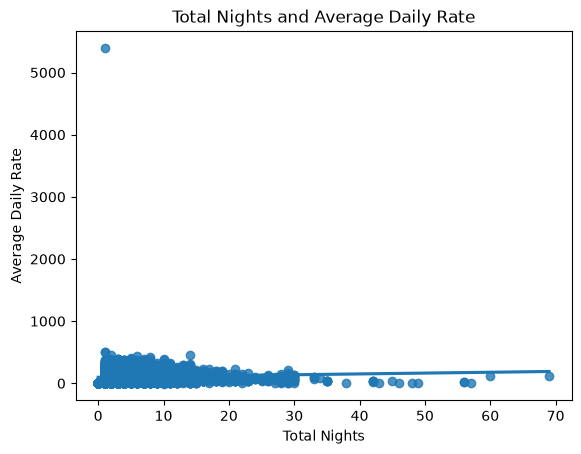

In [54]:
# Another numeric relationship for ADR

sns.regplot(
    data=df,
    x='total_nights',
    y='average_daily_rate'
)

plt.title("Total Nights and Average Daily Rate")
plt.xlabel("Total Nights")
plt.ylabel("Average Daily Rate")
plt.show()


## Final Findings Tables

In [55]:
print("Overall cancellation rate:")
print(round(cancellation_rate * 100, 2), "%")

print("\nHotel cancellation:")
print(hotel_cancellation)

print("\nLead-time cancellation:")
print(lead_cancellation)

print("\nMarket-segment cancellation:")
print(market_cancellation)

print("\nADR-group cancellation:")
print(adr_cancellation)

print("\nCustomer-type cancellation:")
print(customer_cancellation)

print("\nRoom-type cancellation:")
print(room_cancellation)

print("\nGuest-type cancellation:")
print(guest_cancellation)

print("\nTotal potential revenue lost:")
print(round(total_lost_revenue, 2))


Overall cancellation rate:
37.04 %

Hotel cancellation:
hotel
City Hotel      0.417270
Resort Hotel    0.277634
Name: is_canceled, dtype: float64

Lead-time cancellation:
lead_time_group
Immediate         0.096323
Monthly           0.278639
Medium-Term       0.376984
Extended          0.447105
Long-Term         0.554540
Very Long-Term    0.676620
Name: is_canceled, dtype: float64

Market-segment cancellation:
market_segment
Aviation         0.219409
Complementary    0.130552
Corporate        0.187347
Direct           0.153419
Groups           0.610620
Offline TA/TO    0.343160
Online TA        0.367211
Undefined        1.000000
Name: is_canceled, dtype: float64

ADR-group cancellation:
adr_group
low     0.370411
high    1.000000
Name: is_canceled, dtype: float64

Customer-type cancellation:
customer_type
Contract           0.309617
Group              0.102253
Transient          0.407463
Transient-Party    0.254299
Name: is_canceled, dtype: float64

Room-type cancellation:
reserved_room

# Conclusion

The analysis identifies how cancellation behavior differs across hotel type, lead time, market segment, ADR group, customer type, room type, and guest type. Monthly analysis is used to examine cancellation and revenue patterns. Potential lost revenue is calculated from cancelled bookings.

